<a href="https://colab.research.google.com/github/heejaejang/NCAA-Regression-Project/blob/main/Copy_of_NCAA_Regression_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NCAA Scoring Prediction Project

Predicting points per game for 2022 NCAA Division I college basketball players from playing time, efficiency, rebounding, playmaking, and defensive metrics.

**Workflow:** baseline OLS model → diagnostics → revised predictors → Box-Cox-transformed response → partial F tests, influence and multicollinearity checks → stepwise selection by AIC → held-out test set, 5-fold cross-validation, robust standard errors, and a Lasso comparison.

**Author:** Jay Jang

In [135]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats import boxcox
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (6, 4)

# Class-year order; So is the baseline category in every model
YEAR_LEVELS = ["So", "Jr", "Sr"]

# Used to evaluate models on the original points scale
from scipy.special import inv_boxcox
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Model terms, defined once and reused for every formula below
TERMS_1 = ["yr", "Min_per", "ORB_per", "AST_per", "TO_per",
           "twoP_per", "drtg", "TP_per", "dbpm", "yr:Min_per"]   # original model
TERMS_2 = ["yr", "Min_per", "treb", "AST_per", "TO_per",
           "TS_per", "dbpm", "yr:Min_per"]                       # final model
NUMERIC_2 = ["Min_per", "treb", "AST_per", "TO_per", "TS_per", "dbpm"]


def make_formula(response: str, terms: list[str]) -> str:
    """Build a formula string such as 'pts ~ yr + Min_per' from a list of terms."""
    return (f"{response} ~ " + " + ".join(terms)) if terms else f"{response} ~ 1"

# 1. Load data

In [136]:
from pathlib import Path

# Use the local file if it exists; otherwise read the copy in the GitHub repo
# (so the notebook runs in Colab without uploading anything)
DATA_PATH = "data/CollegeBasketballPlayers2022.csv"
DATA_URL = ("https://raw.githubusercontent.com/heejaejang/"
            "NCAA-Regression-Project/main/" + DATA_PATH)

data = pd.read_csv(DATA_PATH if Path(DATA_PATH).exists() else DATA_URL, low_memory=False)
print(data.shape)
print(data["yr"].value_counts())
data.head()

(3978, 66)
yr
Sr    1694
So    1197
Jr    1087
Name: count, dtype: int64


,player_name,team,conf,GP,Min_per,Ortg,usg,eFG,TS_per,ORB_per,DRB_per,AST_per,TO_per,FTM,FTA,FT_per,twoPM,twoPA,twoP_per,TPM,TPA,TP_per,blk_per,stl_per,ftr,yr,ht,num,porpag,adjoe,pfr,year,pid,type,Rec Rank,ast/tov,rimmade,rimmade+rimmiss,midmade,midmade+midmiss,rimmade/(rimmade+rimmiss),midmade/(midmade+midmiss),dunksmade,dunksmiss+dunksmade,dunksmade/(dunksmade+dunksmiss),pick,drtg,adrtg,dporpag,stops,bpm,obpm,dbpm,gbpm,mp,ogbpm,dgbpm,oreb,dreb,treb,ast,stl,blk,pts,Unnamed: 64,Unnamed: 65
0,Isaiah Felder,South Carolina St.,MEAC,11,17.6,61.1,18.6,34.7,35.18,2.5,15.7,8.1,30.4,1,2,0.500,2,8,0.250,7,28,0.250,0.0,0.9,5.6,Sr,Jun-00,0.0,-1.110000,57.5491,2.8,2022,39014,all,NaN,0.384583,2.0,4.0,0.0,4.0,0.5000,0.0000,0.0,0.0,NaN,NaN,110.1920,116.0180,0.450228,21.5242,-11.23760,-7.657450,-3.580200,-11.90720,11.5455,-7.49472,-4.412530,0.2727,1.4545,1.7273,0.4545,0.1818,0.0000,2.3636,Wing G,12.226400
1,Jalen Coleman-Lands,Kansas,B12,23,78.5,103.1,21.5,54.0,56.12,3.6,10.2,7.8,16.1,31,36,0.861,62,129,0.481,58,147,0.395,0.3,1.4,13.0,Sr,4-Jun,5.0,2.977030,111.4260,3.5,2022,40204,all,92.8,0.586950,14.0,26.0,48.0,103.0,0.5385,0.4660,0.0,0.0,NaN,NaN,111.7920,104.3060,2.610670,114.5310,1.06444,2.419920,-1.355480,1.87461,32.7826,2.89361,-1.019000,1.0435,2.8696,3.9130,1.1739,0.8261,0.0870,14.3043,Wing G,11.095900
2,K.J. Walton,Akron,MAC,20,63.0,108.6,26.5,54.3,58.88,9.1,12.6,8.9,17.2,73,92,0.793,127,231,0.550,0,3,0.000,0.7,2.4,39.3,Sr,3-Jun,1.0,3.097360,116.1010,3.3,2022,41728,all,74.0,0.479167,101.0,153.0,39.0,99.0,0.6601,0.3939,4.0,4.0,1.0,NaN,102.6870,101.1810,2.618340,115.7970,1.20190,1.147480,0.054417,2.45207,29.3000,2.78785,-0.335789,2.3500,3.5500,5.9000,1.1500,1.2500,0.2000,16.3500,Wing G,0.284581
3,Jeriah Horne,Tulsa,Amer,32,61.3,116.0,20.8,55.2,58.61,5.8,23.0,7.5,13.0,48,53,0.906,71,139,0.511,52,131,0.397,0.3,1.5,19.6,Sr,7-Jun,41.0,3.277890,123.8120,2.6,2022,44216,all,65.0,0.828488,38.0,59.0,33.0,80.0,0.6441,0.4125,3.0,5.0,0.6,NaN,94.5248,89.0636,3.246900,156.5940,5.48359,4.021870,1.461720,6.94537,24.5000,5.22379,1.721580,1.1250,4.7188,5.8438,0.9062,0.5938,0.0625,10.8125,Stretch 4,10.140700
4,Eric Curry,Minnesota,B10,29,39.2,95.1,14.7,46.3,48.72,7.0,13.7,10.2,20.7,18,29,0.621,38,74,0.514,4,21,0.190,1.5,2.9,30.5,Sr,9-Jun,24.0,0.435561,93.2541,4.9,2022,44217,all,77.4,0.959981,18.0,30.0,20.0,43.0,0.6000,0.4651,0.0,0.0,NaN,NaN,100.1820,93.0315,1.863740,94.0276,2.45292,-0.559305,3.012220,1.49355,15.8966,-1.25322,2.746770,1.1034,1.9655,3.0690,0.8276,0.8276,0.2414,3.6552,Wing F,2.562430


# 2. Clean data for the original model

In [137]:
def clean_players(df, cols, pct_cols, extra_filter=None, id_cols=()):
    """Select columns, drop missing rows, and remove impossible values.

    pct_cols must lie in [0, 100]; extra_filter is an optional function that
    returns a boolean mask for model-specific rules; id_cols (e.g. player name)
    are carried along but not used for filtering.
    """
    out = df[[*id_cols, *cols]].dropna(subset=cols).copy()
    keep = out[pct_cols].apply(lambda s: s.between(0, 100)).all(axis=1)
    keep &= out["dbpm"] < 100
    if extra_filter is not None:
        keep &= extra_filter(out)
    out = out[keep].copy()
    out["yr"] = pd.Categorical(out["yr"], categories=YEAR_LEVELS)
    return out.dropna(subset=["yr"]).reset_index(drop=True)


data_clean = clean_players(
    data,
    cols=["pts", "yr", "Min_per", "ORB_per", "AST_per", "TO_per",
          "twoP_per", "drtg", "TP_per", "dbpm"],
    pct_cols=["ORB_per", "AST_per", "TO_per", "twoP_per", "TP_per"],
    extra_filter=lambda d: (d["pts"] >= 0) & (d["Min_per"] >= 0)
                           & d["drtg"].between(0, 200, inclusive="left"),
)
data_clean.shape   # expect (3781, 10)

(3781, 10)

# 3. Fit the original model

In [138]:
# yr is already a categorical with So as the first level, so it is used directly
formula_original = make_formula("pts", TERMS_1)

model = smf.ols(formula_original, data=data_clean).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    pts   R-squared:                       0.767
Model:                            OLS   Adj. R-squared:                  0.766
Method:                 Least Squares   F-statistic:                     1035.
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:26:54   Log-Likelihood:                -8481.0
No. Observations:                3781   AIC:                         1.699e+04
Df Residuals:                    3768   BIC:                         1.707e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            3.1910      0.655  

# 4. Original model diagnostics

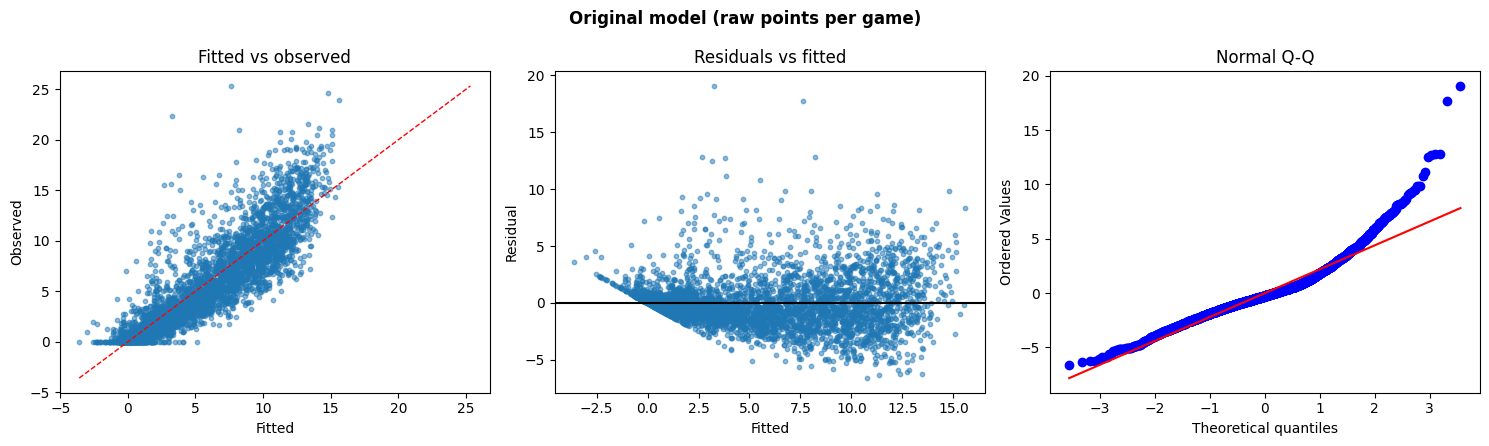

In [139]:
def plot_diagnostics(fitted_model, y: pd.Series, title: str) -> None:
    """Fitted vs observed, residuals vs fitted, and a normal Q-Q plot for an OLS fit."""
    fitted, resid = fitted_model.fittedvalues, fitted_model.resid
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

    axes[0].scatter(fitted, y, s=10, alpha=0.5)
    lims = [min(fitted.min(), y.min()), max(fitted.max(), y.max())]
    axes[0].plot(lims, lims, "r--", linewidth=1)          # perfect-prediction line
    axes[0].set(xlabel="Fitted", ylabel="Observed", title="Fitted vs observed")

    axes[1].scatter(fitted, resid, s=10, alpha=0.5)
    axes[1].axhline(0, color="black")
    axes[1].set(xlabel="Fitted", ylabel="Residual", title="Residuals vs fitted")

    stats.probplot(resid, dist="norm", plot=axes[2])
    axes[2].set_title("Normal Q-Q")

    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_resid_vs_predictors(fitted_model, df: pd.DataFrame, cols: list[str], title: str) -> None:
    """Residuals against each predictor, to look for missed non-linearity."""
    fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 3.5), sharey=True)
    for ax, col in zip(np.atleast_1d(axes), cols):
        x = df[col].cat.codes if isinstance(df[col].dtype, pd.CategoricalDtype) else df[col]
        ax.scatter(x, fitted_model.resid, s=8, alpha=0.5)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xlabel(col + (" (0=So, 1=Jr, 2=Sr)" if col == "yr" else ""))
    np.atleast_1d(axes)[0].set_ylabel("Residual")
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()


plot_diagnostics(model, data_clean["pts"], "Original model (raw points per game)")

# 5. Distributions of the response and predictors

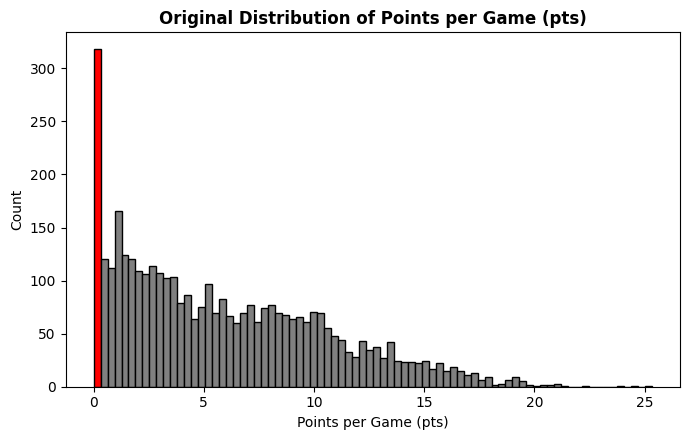

In [140]:
# Histogram of pts, with the first bin highlighted in red
counts, bins = np.histogram(data_clean["pts"], bins=80)
bar_colors = ["red"] + ["grey"] * (len(counts) - 1)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(bins[:-1], counts, width=np.diff(bins), align="edge",
       color=bar_colors, edgecolor="black")
ax.set_title("Original Distribution of Points per Game (pts)", fontweight="bold")
ax.set_xlabel("Points per Game (pts)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


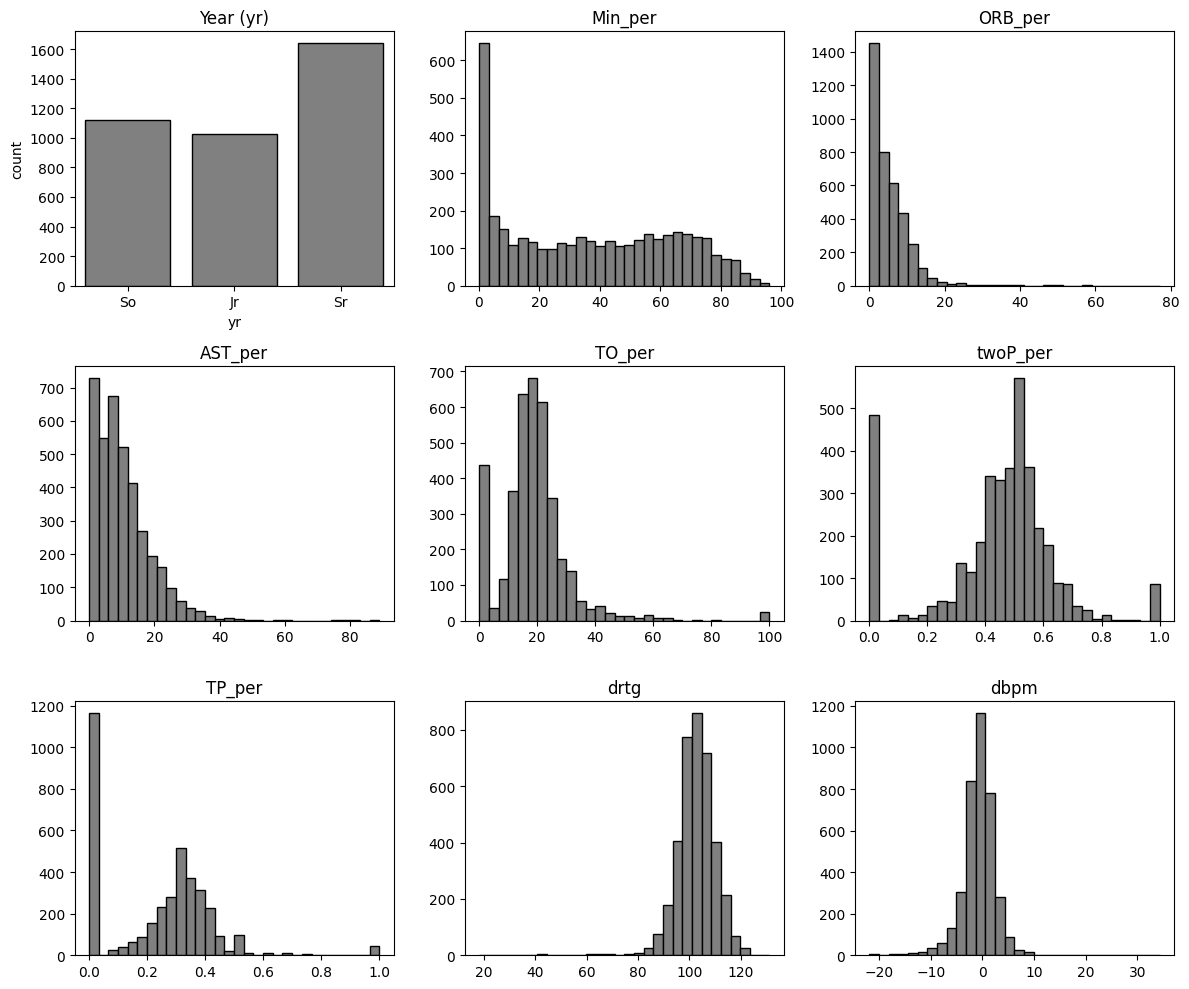

In [141]:
# Class-year counts plus a histogram of each predictor in the original model
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes = axes.flatten()

sns.countplot(x="yr", data=data_clean, color="grey", edgecolor="black", ax=axes[0])
axes[0].set_title("Year (yr)")

for ax, var in zip(axes[1:], ["Min_per", "ORB_per", "AST_per", "TO_per",
                              "twoP_per", "TP_per", "drtg", "dbpm"]):
    ax.hist(data_clean[var], bins=30, color="grey", edgecolor="black")
    ax.set_title(var)

plt.tight_layout()
plt.show()

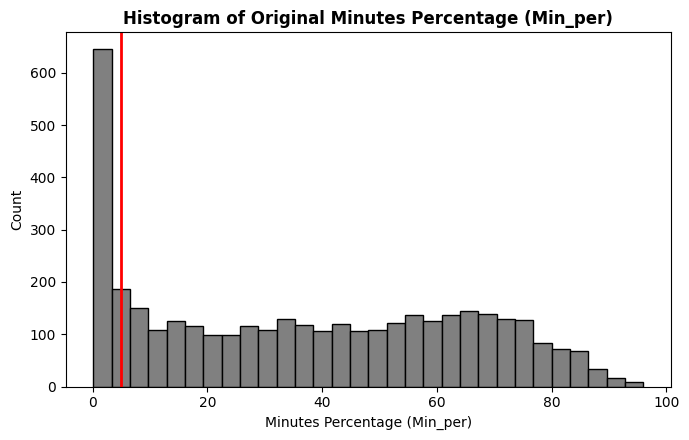

In [142]:
# Histogram of Min_per with a vertical reference line at 5
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(data_clean["Min_per"], bins=30, color="grey", edgecolor="black")
ax.axvline(5, color="red", linewidth=2)
ax.set_title("Histogram of Original Minutes Percentage (Min_per)", fontweight="bold")
ax.set_xlabel("Minutes Percentage (Min_per)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


# 6. Interaction: minutes by class year

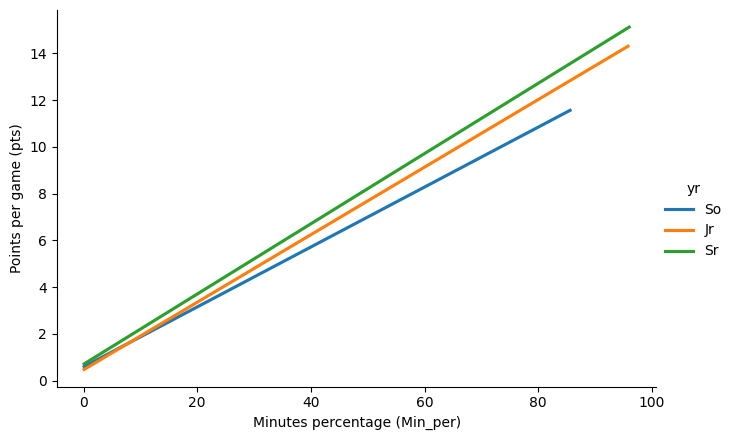

In [143]:
# One fitted line per class year; non-parallel lines suggest a yr x Min_per interaction
g = sns.lmplot(x="Min_per", y="pts", hue="yr", hue_order=YEAR_LEVELS, data=data_clean,
               scatter=False, ci=None, height=4.5, aspect=1.5)
g.set_axis_labels("Minutes percentage (Min_per)", "Points per game (pts)")
plt.show()

# 7. Correlation matrix (original predictors)

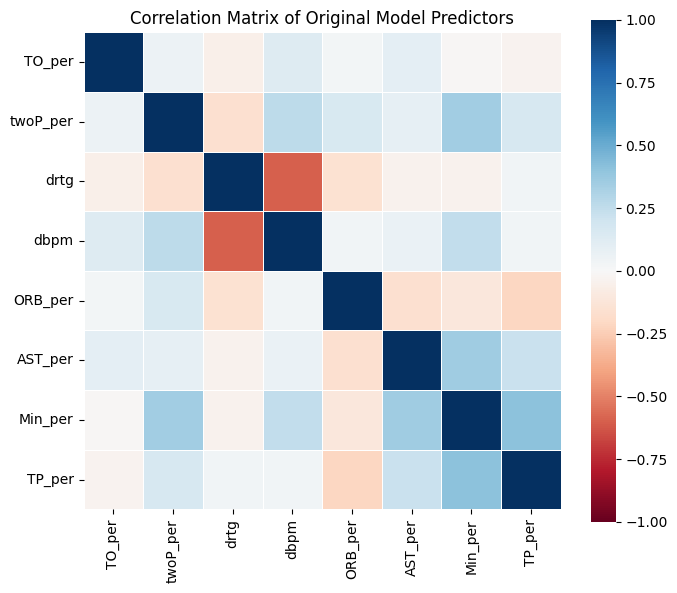

In [144]:
numeric_predictors = data_clean[["Min_per", "ORB_per", "AST_per", "TO_per",
                                  "twoP_per", "drtg", "TP_per", "dbpm"]]

cor_matrix = numeric_predictors.corr()

# Order variables by hierarchical clustering on 1 - |r| so correlated predictors sit together
dist = 1 - cor_matrix.abs()
condensed = squareform(dist.values, checks=False)
link = linkage(condensed, method="average")
order = leaves_list(link)
ordered_cols = cor_matrix.columns[order]
cor_matrix_ordered = cor_matrix.loc[ordered_cols, ordered_cols]

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cor_matrix_ordered, cmap="RdBu", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar=True, ax=ax)
ax.set_title("Correlation Matrix of Original Model Predictors")
plt.tight_layout()
plt.show()


# 8. Clean data for the Box-Cox model

In [145]:
# Box-Cox needs pts > 0; Min_per > 5 removes deep-bench players (see histogram above)
data_clean2 = clean_players(
    data,
    cols=["pts", "yr", "Min_per", "treb", "AST_per", "TO_per", "TS_per", "dbpm"],
    pct_cols=["treb", "AST_per", "TO_per", "TS_per"],
    extra_filter=lambda d: (d["pts"] > 0) & (d["Min_per"] > 5),
    id_cols=["player_name", "team"],   # kept so influential points can be named
)
data_clean2.shape  # expect (3022, 10)

(3022, 10)

# 9. Fit model 2 on raw points

In [146]:
formula_final = make_formula("pts", TERMS_2)

model_final = smf.ols(formula_final, data=data_clean2).fit()
print(model_final.summary())

                            OLS Regression Results                            
Dep. Variable:                    pts   R-squared:                       0.781
Model:                            OLS   Adj. R-squared:                  0.780
Method:                 Least Squares   F-statistic:                     1073.
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:26:57   Log-Likelihood:                -6491.0
No. Observations:                3022   AIC:                         1.300e+04
Df Residuals:                    3011   BIC:                         1.307e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -2.8920      0.311  

# 10. Box-Cox transformation

Estimated lambda: 0.4351


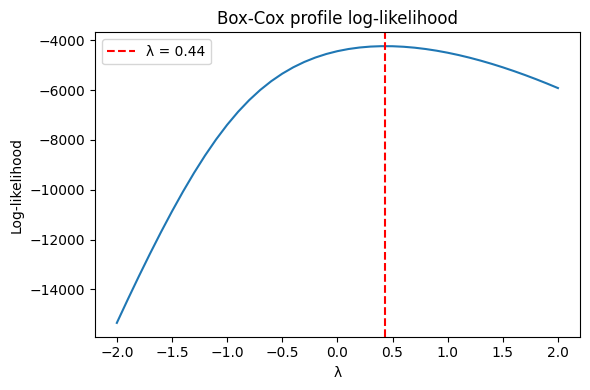

In [147]:
# boxcox returns the transformed values AND the maximum-likelihood estimate of lambda
data_clean2["bc_pts"], lambda_ = boxcox(data_clean2["pts"])
print(f"Estimated lambda: {lambda_:.4f}")

# Profile log-likelihood across a grid of lambda values
lambdas = np.linspace(-2, 2, 41)
llf = [stats.boxcox_llf(l, data_clean2["pts"]) for l in lambdas]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(lambdas, llf)
ax.axvline(lambda_, color="red", linestyle="--", label=f"λ = {lambda_:.2f}")
ax.set(xlabel="λ", ylabel="Log-likelihood", title="Box-Cox profile log-likelihood")
ax.legend()
plt.tight_layout()
plt.show()

# 11. Fit the Box-Cox model

In [148]:
formula_bc = make_formula("bc_pts", TERMS_2)

model_bc = smf.ols(formula_bc, data=data_clean2).fit()
print(model_bc.summary())

                            OLS Regression Results                            
Dep. Variable:                 bc_pts   R-squared:                       0.832
Model:                            OLS   Adj. R-squared:                  0.832
Method:                 Least Squares   F-statistic:                     1494.
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:26:57   Log-Likelihood:                -2872.0
No. Observations:                3022   AIC:                             5766.
Df Residuals:                    3011   BIC:                             5832.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -1.1345      0.094  

# 12. Box-Cox model diagnostics

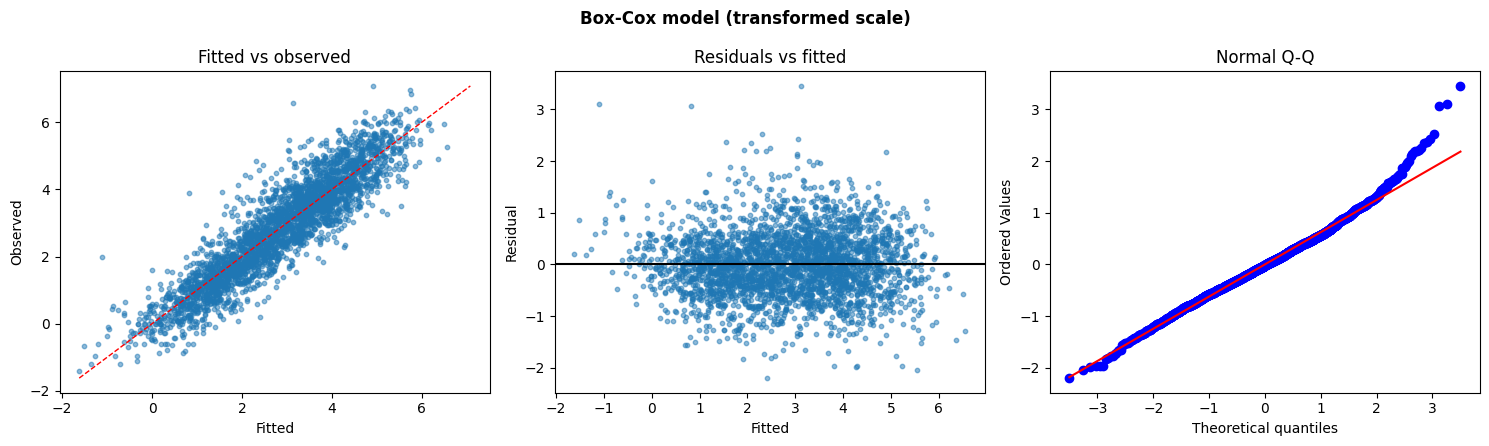

In [149]:
plot_diagnostics(model_bc, data_clean2["bc_pts"], "Box-Cox model (transformed scale)")

# 13. Partial F tests

Each row compares the full Box-Cox model with a reduced model that drops the listed terms. A large F (small p-value) means the dropped terms explain variation the rest of the model cannot.

In [150]:
def fit_terms(df: pd.DataFrame, terms: list[str], response: str = "bc_pts"):
    """Fit an OLS model from a list of formula terms."""
    return smf.ols(make_formula(response, terms), data=df).fit()


def without(terms: list[str], removed: list[str]) -> list[str]:
    """Return terms with the given terms removed."""
    return [t for t in terms if t not in removed]


# Each reduced model drops these terms from the full Box-Cox model
drops = {
    "AST_per": ["AST_per"],
    "TO_per": ["TO_per"],
    "TS_per": ["TS_per"],
    "yr:Min_per (interaction)": ["yr:Min_per"],
    "Min_per (with its interaction)": ["Min_per", "yr:Min_per"],
    "skills (treb, AST_per, TO_per, TS_per)": ["treb", "AST_per", "TO_per", "TS_per"],
    "everything except Min_per and yr:Min_per": ["yr", "treb", "AST_per", "TO_per", "TS_per", "dbpm"],
}

rows = []
for label, removed in drops.items():
    reduced = fit_terms(data_clean2, without(TERMS_2, removed))
    f_row = anova_lm(reduced, model_bc).iloc[1]
    rows.append({"dropped": label, "df": int(f_row["df_diff"]),
                 "F": f_row["F"], "p-value": f_row["Pr(>F)"]})

partial_f = pd.DataFrame(rows).set_index("dropped")
partial_f.style.format({"F": "{:.2f}", "p-value": "{:.3g}"})

,df,F,p-value
dropped,,,
AST_per,1,501.37,7.61e-103
TO_per,1,358.53,1.24e-75
TS_per,1,520.00,2.62e-106
yr:Min_per (interaction),2,3.97,0.019
Min_per (with its interaction),3,625.37,5.84e-316
"skills (treb, AST_per, TO_per, TS_per)",4,531.67,0
everything except Min_per and yr:Min_per,7,336.16,0


# 14. Influence diagnostics

In [151]:
def influence_summary(fitted_model, df: pd.DataFrame, outlier_cut: float = 2.0, top: int = 5):
    """Count observations flagged by each influence measure and return the top cases by Cook's D.

    Cutoffs: leverage 2(p+1)/n, |studentized residual| > outlier_cut,
    Cook's D > F(0.5; p+1, n-p-1), |DFFITS| > 2*sqrt((p+1)/n), any |DFBETAS| > 2/sqrt(n).
    """
    infl = fitted_model.get_influence()
    n, k = len(df), len(fitted_model.params)          # k = p + 1

    cuts = {
        "leverage": 2 * k / n,
        "outlier": outlier_cut,
        "cooks_d": stats.f.ppf(0.5, k, n - k),
        "dffits": 2 * np.sqrt(k / n),
        "dfbetas": 2 / np.sqrt(n),
    }
    flags = pd.DataFrame({
        "leverage": infl.hat_matrix_diag > cuts["leverage"],
        "outlier": np.abs(infl.resid_studentized_internal) > cuts["outlier"],
        "cooks_d": infl.cooks_distance[0] > cuts["cooks_d"],
        "dffits": np.abs(infl.dffits[0]) > cuts["dffits"],
        "dfbetas": (np.abs(infl.dfbetas) > cuts["dfbetas"]).any(axis=1),
    })

    summary = pd.DataFrame({"cutoff": pd.Series(cuts), "n_flagged": flags.sum()})
    summary["pct"] = (100 * summary["n_flagged"] / n).round(1)

    top_cases = (df.assign(cooks_d=infl.cooks_distance[0],
                           leverage=infl.hat_matrix_diag,
                           std_resid=infl.resid_studentized_internal)
                   .nlargest(top, "cooks_d"))
    return summary, top_cases


SHOW_COLS = ["player_name", "team", "yr", "pts", "Min_per", "cooks_d", "leverage", "std_resid"]

summary_bc, top_bc = influence_summary(model_bc, data_clean2, outlier_cut=4)
display(summary_bc.round(4))
print("Most influential players (largest Cook's distance):")
display(top_bc[SHOW_COLS].round(4))

,cutoff,n_flagged,pct
leverage,0.0073,199,6.6
outlier,4.0000,4,0.1
cooks_d,0.9403,0,0.0
dffits,0.1207,180,6.0
dfbetas,0.0364,700,23.2


Most influential players (largest Cook's distance):


,player_name,team,yr,pts,Min_per,cooks_d,leverage,std_resid
3006,Heri Ngalamulume,Tarleton St.,Sr,4.2000,8.7,0.0335,0.0146,4.9918
802,AJ Green,Northern Iowa,Sr,22.3333,11.7,0.0224,0.0080,5.5325
432,Chris Lykes,Arkansas,Sr,15.5000,5.3,0.0166,0.0175,3.2075
2876,Brock Gilbert,Dixie St.,Sr,1.2222,23.4,0.0157,0.0136,-3.5352
1629,Caleb Mills,Florida St.,Jr,9.7500,6.1,0.0114,0.0052,4.9117


# 15. Multicollinearity check (VIF)

In [152]:
def design_matrix(df: pd.DataFrame) -> pd.DataFrame:
    """Numeric predictors plus year dummies (So is the baseline), as floats."""
    return pd.get_dummies(df[["yr", *NUMERIC_2]], columns=["yr"], drop_first=True).astype(float)


def vif_table(df: pd.DataFrame) -> pd.DataFrame:
    """Variance inflation factor for each predictor in the final model (intercept excluded)."""
    X = sm.add_constant(design_matrix(df))
    vifs = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return (pd.DataFrame({"variable": X.columns, "VIF": vifs})
              .query("variable != 'const'")
              .reset_index(drop=True))


vif_table(data_clean2).round(3)

,variable,VIF
0,Min_per,2.248
1,treb,1.919
2,AST_per,1.371
3,TO_per,1.144
4,TS_per,1.154
5,dbpm,1.186
6,yr_Jr,1.607
7,yr_Sr,1.766


# 16. Predicted interaction effect

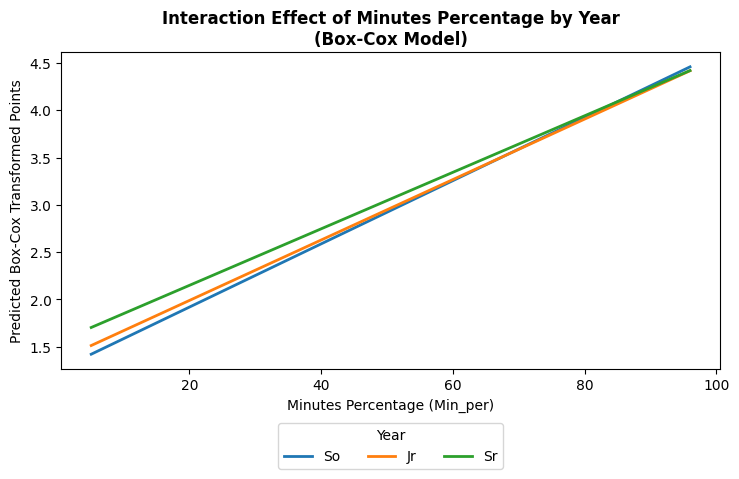

In [153]:
# Predicted Box-Cox points across the range of Min_per for each class year,
# holding the other predictors at their sample means
min_per_seq = np.linspace(data_clean2["Min_per"].min(), data_clean2["Min_per"].max(), 200)
means = data_clean2[NUMERIC_2].mean().to_dict()

newdata = pd.DataFrame([{**means, "Min_per": m, "yr": y}
                        for m in min_per_seq for y in YEAR_LEVELS])
newdata["yr"] = pd.Categorical(newdata["yr"], categories=YEAR_LEVELS)
newdata["pred"] = model_bc.predict(newdata)

fig, ax = plt.subplots(figsize=(7.5, 5))
for year, sub in newdata.groupby("yr", observed=True):
    ax.plot(sub["Min_per"], sub["pred"], linewidth=2, label=year)

ax.set_title("Interaction Effect of Minutes Percentage by Year\n(Box-Cox Model)", fontweight="bold")
ax.set_xlabel("Minutes Percentage (Min_per)")
ax.set_ylabel("Predicted Box-Cox Transformed Points")
ax.legend(title="Year", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.tight_layout()
plt.show()

# 17. Stepwise selection by AIC

A greedy search over model terms: at each step it tries adding or removing one term and keeps the move that lowers AIC the most, stopping when no move helps. `yr` and `yr:Min_per` are each treated as a single term. Stepwise selection can overstate significance, so section 21 also scores the selected model with cross-validation.

In [154]:
def stepwise_selection(df: pd.DataFrame, all_terms: list[str], response: str = "bc_pts",
                       direction: str = "both", verbose: bool = True):
    """Greedy stepwise selection by AIC.

    direction: "forward" starts from the intercept-only model, "backward" from the
    full model, and "both" from the full model, allowing additions and removals.
    Returns (fitted model, selected terms).
    """
    current = [] if direction == "forward" else list(all_terms)
    current_aic = fit_terms(df, current, response).aic

    while True:
        moves = []
        if direction in ("backward", "both"):
            moves += [("remove", t, without(current, [t])) for t in current]
        if direction in ("forward", "both"):
            moves += [("add", t, current + [t]) for t in all_terms if t not in current]
        if not moves:
            break

        scored = [(fit_terms(df, trial, response).aic, action, t, trial)
                  for action, t, trial in moves]
        best_aic, action, term, trial = min(scored, key=lambda m: m[0])
        if best_aic >= current_aic:
            break
        if verbose:
            print(f"{action:>6}: {term:<12} AIC {current_aic:.2f} -> {best_aic:.2f}")
        current, current_aic = trial, best_aic

    return fit_terms(df, current, response), current


# Bidirectional search starting from the full model
model_stepwise, terms_stepwise = stepwise_selection(data_clean2, TERMS_2, direction="both")
print(f"Selected terms ({len(terms_stepwise)} of {len(TERMS_2)}): {', '.join(terms_stepwise)}")
print(f"AIC: full model {model_bc.aic:.2f} | stepwise model {model_stepwise.aic:.2f}")

Selected terms (8 of 8): yr, Min_per, treb, AST_per, TO_per, TS_per, dbpm, yr:Min_per
AIC: full model 5766.01 | stepwise model 5766.01


# 18. Train/test split

80/20 split with a fixed seed. λ is estimated on the training set only and reused on the test set, so the test data never influences the transformation.

In [155]:
SEED = 67

# Split the cleaned data, leaving out the bc_pts column computed on the full sample
model_data = data_clean2.drop(columns="bc_pts")
train, test = train_test_split(model_data, test_size=0.2, random_state=SEED)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

# Estimate lambda on the training set only, then apply that same lambda to the test set,
# so no information from the test set leaks into the transformation
train["bc_pts"], lambda_train = boxcox(train["pts"])
test["bc_pts"] = boxcox(test["pts"], lmbda=lambda_train)

print(f"Train: {len(train)} | Test: {len(test)} | "
      f"lambda (train): {lambda_train:.4f} | lambda (full data): {lambda_:.4f}")

Train: 2417 | Test: 605 | lambda (train): 0.4339 | lambda (full data): 0.4351


# 19. Out-of-sample evaluation

Both models are fitted on the training set only and scored on the 605 held-out players, with Box-Cox predictions transformed back to points.

In [156]:
# Fit on the training set only, then predict the held-out test set
model_train = smf.ols(formula_bc, data=train).fit()
model_raw_train = smf.ols(formula_final, data=train).fit()   # baseline: untransformed pts
print(model_train.summary())

test_preds = {
    "Raw pts model": model_raw_train.predict(test),
    "Box-Cox model": inv_boxcox(model_train.predict(test), lambda_train),  # back to points
}
test_results = pd.DataFrame({
    name: {"RMSE (pts)": mean_squared_error(test["pts"], pred) ** 0.5,
           "MAE (pts)": mean_absolute_error(test["pts"], pred),
           "R² (pts)": r2_score(test["pts"], pred)}
    for name, pred in test_preds.items()
}).T.round(3)
test_results

                            OLS Regression Results                            
Dep. Variable:                 bc_pts   R-squared:                       0.834
Model:                            OLS   Adj. R-squared:                  0.833
Method:                 Least Squares   F-statistic:                     1205.
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:27:03   Log-Likelihood:                -2262.7
No. Observations:                2417   AIC:                             4547.
Df Residuals:                    2406   BIC:                             4611.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -1.1553      0.104  

,RMSE (pts),MAE (pts),R² (pts)
Raw pts model,2.225,1.635,0.766
Box-Cox model,2.166,1.517,0.778


# 20. Robust standard errors (HC3)

The residual plots show some unequal spread, so the Box-Cox model is refitted with HC3 heteroskedasticity-consistent standard errors. The coefficients are identical; only the standard errors and p-values change.

In [157]:
model_bc_hc3 = smf.ols(formula_bc, data=data_clean2).fit(cov_type="HC3")

robust_compare = pd.DataFrame({
    "coef": model_bc.params,
    "OLS SE": model_bc.bse, "HC3 SE": model_bc_hc3.bse,
    "OLS p": model_bc.pvalues, "HC3 p": model_bc_hc3.pvalues,
})
robust_compare.round(4)

,coef,OLS SE,HC3 SE,OLS p,HC3 p
Intercept,-1.1345,0.0939,0.1016,0.0000,0.0000
yr[T.Jr],0.0994,0.0647,0.0683,0.1246,0.1453
yr[T.Sr],0.3008,0.0596,0.0625,0.0000,0.0000
Min_per,0.0334,0.0012,0.0012,0.0000,0.0000
yr[T.Jr]:Min_per,-0.0015,0.0015,0.0015,0.3181,0.3189
yr[T.Sr]:Min_per,-0.0035,0.0013,0.0013,0.0078,0.0060
treb,0.2581,0.0083,0.0104,0.0000,0.0000
AST_per,0.0413,0.0018,0.0023,0.0000,0.0000
TO_per,-0.0339,0.0018,0.0019,0.0000,0.0000
TS_per,0.0330,0.0014,0.0017,0.0000,0.0000


# 21. 5-fold cross-validation

A single train/test split depends on which players happen to land in the test set. K-fold cross-validation repeats the evaluation on 5 different splits. λ is re-estimated inside each training fold, and errors are reported in points per game. This is also a fair test of the stepwise result: AIC chooses terms on the same data it is scored on, while cross-validation scores each candidate on held-out players.

In [158]:
def cv_scores(df: pd.DataFrame, terms: list[str], transform: bool = True,
              n_splits: int = 5, seed: int = SEED) -> dict:
    """K-fold RMSE and MAE in points; Box-Cox lambda is re-estimated inside each training fold."""
    rmse, mae = [], []
    for tr_idx, te_idx in KFold(n_splits, shuffle=True, random_state=seed).split(df):
        tr, te = df.iloc[tr_idx].copy(), df.iloc[te_idx]
        if transform:
            tr["bc_pts"], lam = boxcox(tr["pts"])
            m = smf.ols(make_formula("bc_pts", terms), data=tr).fit()
            pred = inv_boxcox(m.predict(te), lam)
        else:
            m = smf.ols(make_formula("pts", terms), data=tr).fit()
            pred = m.predict(te)
        rmse.append(mean_squared_error(te["pts"], pred) ** 0.5)
        mae.append(mean_absolute_error(te["pts"], pred))
    return {"RMSE mean": np.mean(rmse), "RMSE sd": np.std(rmse), "MAE mean": np.mean(mae)}


cv_data = data_clean2.drop(columns="bc_pts")
candidates = {
    "Box-Cox, full model": (TERMS_2, True),
    "Box-Cox, stepwise terms": (terms_stepwise, True),
    "Box-Cox, no interaction": (without(TERMS_2, ["yr:Min_per"]), True),
    "Raw pts, full model": (TERMS_2, False),
}
cv_table = pd.DataFrame({name: cv_scores(cv_data, terms, transform)
                         for name, (terms, transform) in candidates.items()}).T.round(3)
cv_table

,RMSE mean,RMSE sd,MAE mean
"Box-Cox, full model",1.997,0.139,1.435
"Box-Cox, stepwise terms",1.997,0.139,1.435
"Box-Cox, no interaction",2.000,0.141,1.438
"Raw pts, full model",2.080,0.111,1.564


# 22. Regularized comparison: Lasso

As a check on the hand-built OLS model, a scikit-learn pipeline standardizes the same predictors (year dummies and year × minutes interactions included) and fits a Lasso, with the penalty chosen by inner cross-validation. It predicts raw points on the same 5 folds as section 21, so its RMSE compares directly with that table.

In [159]:
X = design_matrix(cv_data)
for lvl in ["Jr", "Sr"]:
    X[f"yr_{lvl}:Min_per"] = X[f"yr_{lvl}"] * X["Min_per"]
y = cv_data["pts"]

lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=SEED))
outer_cv = KFold(5, shuffle=True, random_state=SEED)
lasso_rmse = -cross_val_score(lasso, X, y, cv=outer_cv, scoring="neg_root_mean_squared_error")
print(f"Lasso 5-fold RMSE: {lasso_rmse.mean():.3f} ± {lasso_rmse.std():.3f} pts")

lasso.fit(X, y)
lasso_coefs = pd.Series(lasso[-1].coef_, index=X.columns, name="standardized coef")
lasso_coefs.sort_values(key=abs, ascending=False).round(3)

Lasso 5-fold RMSE: 2.080 ± 0.111 pts


,standardized coef
Min_per,1.689
treb,1.484
AST_per,0.946
dbpm,-0.916
TS_per,0.644
TO_per,-0.576
yr_Sr:Min_per,0.538
yr_Jr:Min_per,0.344
yr_Jr,-0.132
yr_Sr,-0.061


# 23. Results and limitations

**Final model.** OLS on Box-Cox-transformed points per game (λ ≈ 0.44, close to a square-root transform), fitted to 3,022 players who played more than 5% of team minutes and scored at least one point. The transformation removed most of the residual skew (skewness 0.77 → 0.34) and gives better predictions in points than the untransformed model.

**Predictive accuracy (points per game)**

| Evaluation | Box-Cox model | Raw-points model |
|---|---|---|
| Held-out test set (n = 605), RMSE | **2.17** | 2.23 |
| Held-out test set, MAE | **1.52** | 1.64 |
| 5-fold cross-validation, RMSE | **2.00 ± 0.14** | 2.08 ± 0.11 |
| Lasso pipeline (raw points), 5-fold RMSE | — | 2.08 ± 0.11 |

**Key findings**
- **Playing time** is the strongest predictor of scoring (largest standardized Lasso coefficient; dropping it and its interaction gives F ≈ 625, p ≈ 10⁻³¹⁶).
- **Rebounding, assist rate, and true-shooting %** are associated with more points, while **turnover rate** and **defensive BPM** are associated with fewer, holding the other predictors fixed.
- The **class year × minutes interaction** is statistically detectable (partial F p = 0.019) but practically negligible: removing it changes cross-validated RMSE by only about 0.003 points. Stepwise selection by AIC kept all eight terms.
- The Lasso matched the raw OLS model and shrank no coefficient to zero. With all VIFs below 2.5, the predictors aren't redundant, so regularization adds little here.
- **Influence:** no player exceeds the Cook's distance cutoff (largest D ≈ 0.03). HC3 robust standard errors are slightly larger, but every conclusion about significance is unchanged.

**Limitations**
- One season of data, so the results may not carry over to other seasons.
- Players with under 5% of minutes or zero points are excluded, and the dataset contains no freshmen.
- The associations are observational, not causal. Minutes partly reflect scoring ability, because coaches give more minutes to players who score.
- Back-transformed predictions estimate the *median* points per game, not the mean.